# 2 - does success fall late in games?


In [ ]:
from abs_common import *            

All tables agree: 10,557 challenges, 5,685 overturned (53.9%), 4,858 team-games.


2 challenges left, innings 1-3: 60.7% (n=2,776, 95% CI 58.8%-62.5%)
2 challenges left, innings 8-9: 40.4% (n=1,409, 95% CI 37.9%-43.0%)
difference 20.3 points, z = 12.4


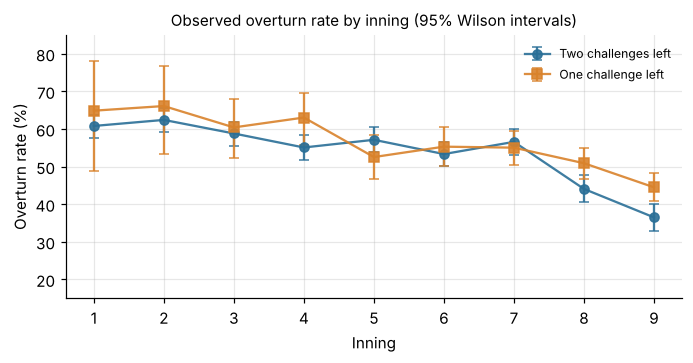

In [2]:
early, late = reg.loc[1:3], reg.loc[8:9]
ke, ne = early.k2.sum(), early.n2.sum()
kl, nl = late.k2.sum(), late.n2.sum()
z_p1 = ztest(ke, ne, kl, nl)
print(f"2 challenges left, innings 1-3: {pct(ke/ne)} (n={ne:,}, 95% CI {pct(wilson(ke,ne)[0])}-{pct(wilson(ke,ne)[1])})")
print(f"2 challenges left, innings 8-9: {pct(kl/nl)} (n={nl:,}, 95% CI {pct(wilson(kl,nl)[0])}-{pct(wilson(kl,nl)[1])})")
print(f"difference {100*(ke/ne-kl/nl):.1f} points, z = {z_p1:.1f}")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for lab, n, k, c, mk in (("Two challenges left","n2","k2",BLUE,"o"), ("One challenge left","n1","k1",ORANGE,"s")):
    r = reg[k] / reg[n]
    ci = np.array([wilson(a, b) for a, b in zip(reg[k], reg[n])])
    ax.errorbar(reg.index, 100*r, yerr=[100*(r-ci[:,0]), 100*(ci[:,1]-r)], fmt=mk+"-", color=c,
                capsize=3, label=lab, alpha=.9)
ax.set_xlabel("Inning"); ax.set_ylabel("Overturn rate (%)"); ax.set_ylim(15, 85)
ax.set_title("Observed overturn rate by inning (95% Wilson intervals)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

Interval widths show where the data are thin: with one challenge left, innings 1-2 have only 37 and 59 challenges, so the early orange points are noisy.